In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from bookrec.data import (
    load_ratings,
    load_books,
    load_book_tags
)

from bookrec.plot_style import setup, save

# Apply the team's common plotting style
setup()

print("Libraries and plotting style loaded successfully.")


Libraries and plotting style loaded successfully.


In [2]:

# Load the original Goodbooks-10k datasets
ratings = load_ratings()
books = load_books()
book_tags = load_book_tags()

print("Data loaded successfully!")

print("Ratings:", ratings.shape)
print("Books:", books.shape)
print("Book Tags:", book_tags.shape)


Data loaded successfully!
Ratings: (5976479, 3)
Books: (10000, 23)
Book Tags: (999898, 3)


In [3]:

# Check the first five rows
display(ratings.head())
display(books.head())
display(book_tags.head())

# Check missing values
print("\nMissing values in ratings:")
print(ratings.isnull().sum())

print("\nMissing values in books:")
print(books.isnull().sum())

print("\nMissing values in book_tags:")
print(book_tags.isnull().sum())


,user_id,book_id,rating
0,1,258,5
1,2,4081,4
2,2,260,5
3,2,9296,5
4,2,2318,3


,book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,title,...,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url,main_author
0,1,2767052,2792775,272,439023483,9.780439e+12,[Suzanne Collins],2008.0,The Hunger Games,"The Hunger Games (The Hunger Games, #1)",...,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...,Suzanne Collins
1,2,3,4640799,491,439554934,9.780440e+12,"[J.K. Rowling, Mary GrandPré]",1997.0,Harry Potter and the Philosopher's Stone,Harry Potter and the Sorcerer's Stone (Harry P...,...,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...,J.K. Rowling
2,3,41865,3212258,226,316015849,9.780316e+12,[Stephenie Meyer],2005.0,Twilight,"Twilight (Twilight, #1)",...,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...,Stephenie Meyer
3,4,2657,3275794,487,61120081,9.780061e+12,[Harper Lee],1960.0,To Kill a Mockingbird,To Kill a Mockingbird,...,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...,Harper Lee
4,5,4671,245494,1356,743273567,9.780743e+12,[F. Scott Fitzgerald],1925.0,The Great Gatsby,The Great Gatsby,...,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...,F. Scott Fitzgerald


,book_id,tag_name,count
0,1,favorites,50755
1,1,currently-reading,35418
2,1,young-adult,25968
3,1,fiction,13819
4,1,dystopian,12985



Missing values in ratings:
user_id    0
book_id    0
rating     0
dtype: int64

Missing values in books:
book_id                         0
best_book_id                    0
work_id                         0
books_count                     0
isbn                          700
isbn13                        585
authors                         0
original_publication_year      21
original_title                585
title                           0
language_code                1084
average_rating                  0
ratings_count                   0
work_ratings_count              0
work_text_reviews_count         0
ratings_1                       0
ratings_2                       0
ratings_3                       0
ratings_4                       0
ratings_5                       0
image_url                       0
small_image_url                 0
main_author                     0
dtype: int64

Missing values in book_tags:
book_id     0
tag_name    0
count       0
dtype: int64


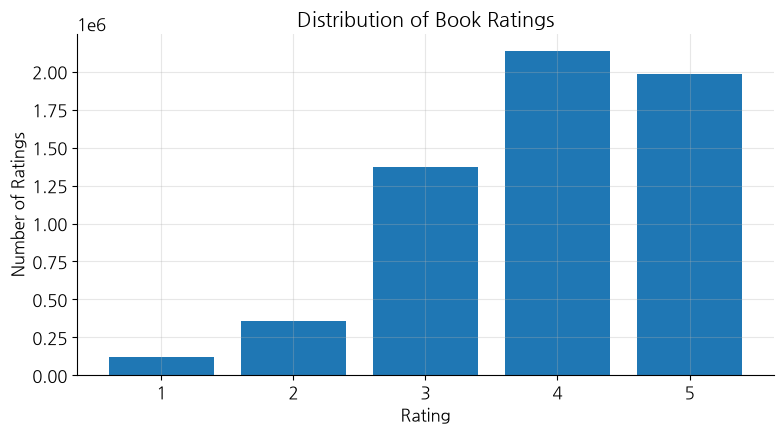

In [4]:

# Rating Distribution

rating_counts = ratings["rating"].value_counts().sort_index()

fig, ax = plt.subplots()

ax.bar(
    rating_counts.index,
    rating_counts.values,
)

ax.set_title("Distribution of Book Ratings")
ax.set_xlabel("Rating")
ax.set_ylabel("Number of Ratings")
ax.set_xticks([1, 2, 3, 4, 5])

save(fig, "d1_rating_distribution")

plt.show()


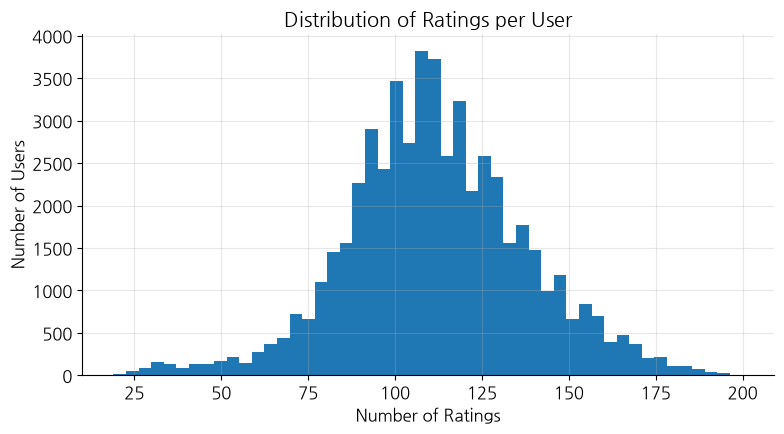

In [5]:

# Number of Ratings per User

user_rating_counts = ratings.groupby("user_id").size()

fig, ax = plt.subplots()

ax.hist(user_rating_counts, bins=50)

ax.set_title("Distribution of Ratings per User")
ax.set_xlabel("Number of Ratings")
ax.set_ylabel("Number of Users")

save(fig, "d1_user_rating_distribution")

plt.show()


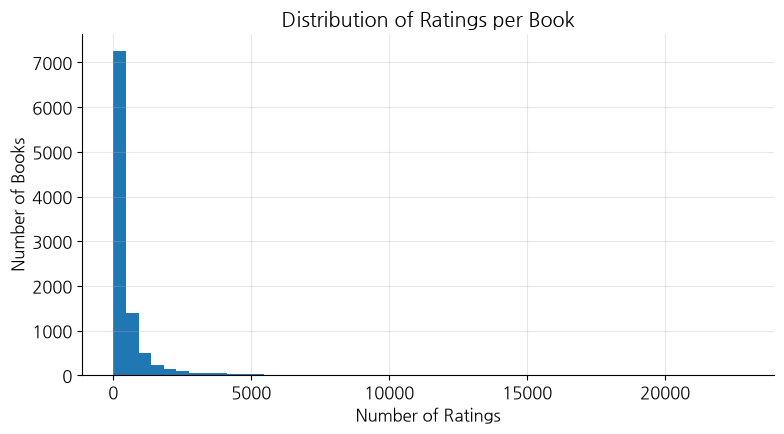

In [6]:

# Number of Ratings per Book

book_rating_counts = ratings.groupby("book_id").size()

fig, ax = plt.subplots()

ax.hist(book_rating_counts, bins=50)

ax.set_title("Distribution of Ratings per Book")
ax.set_xlabel("Number of Ratings")
ax.set_ylabel("Number of Books")

save(fig, "d1_book_rating_distribution")

plt.show()


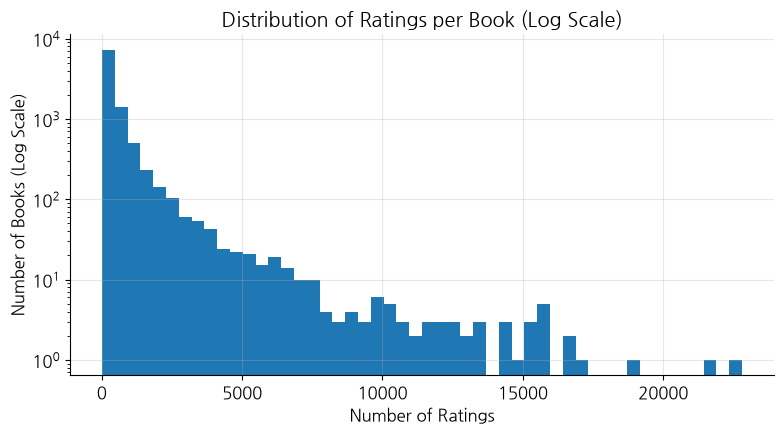

In [7]:
# Ratings per Book (Log Scale)

fig, ax = plt.subplots()

ax.hist(book_rating_counts, bins=50, log=True)

ax.set_title("Distribution of Ratings per Book (Log Scale)")
ax.set_xlabel("Number of Ratings")
ax.set_ylabel("Number of Books (Log Scale)")

save(fig, "d1_book_rating_distribution_log")

plt.show()

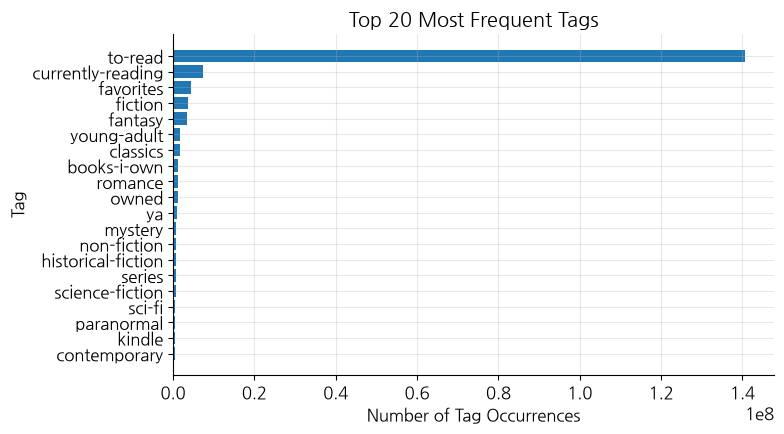

In [8]:
# Top 20 Most Frequent Tags

top_tags = (
    book_tags.groupby("tag_name")["count"]
    .sum()
    .sort_values(ascending=False)
    .head(20)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(top_tags.index, top_tags.values)

ax.set_title("Top 20 Most Frequent Tags")
ax.set_xlabel("Number of Tag Occurrences")
ax.set_ylabel("Tag")

save(fig, "d1_top_20_tags")

plt.show()

In [9]:
# Rating Sparsity

num_users = ratings["user_id"].nunique()
num_books = ratings["book_id"].nunique()
num_ratings = len(ratings)

total_possible_ratings = num_users * num_books
sparsity = 1 - (num_ratings / total_possible_ratings)

print(f"Number of Users: {num_users:,}")
print(f"Number of Books: {num_books:,}")
print(f"Number of Ratings: {num_ratings:,}")
print(f"Rating Sparsity: {sparsity:.4%}")

Number of Users: 53,424
Number of Books: 10,000
Number of Ratings: 5,976,479
Rating Sparsity: 98.8813%


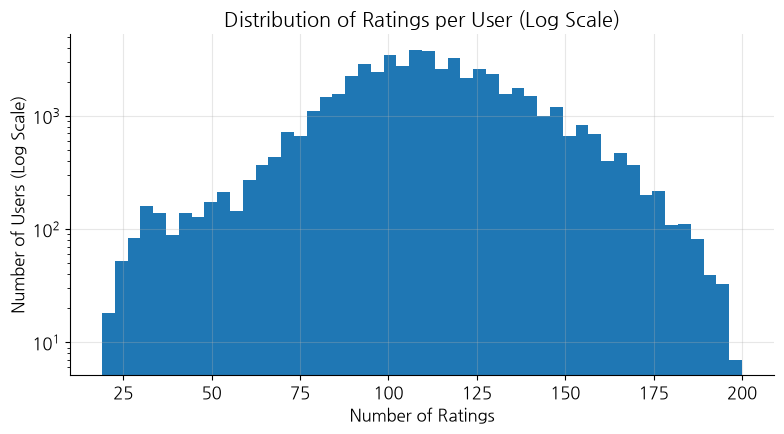

In [10]:
# Ratings per User

user_rating_counts = ratings.groupby("user_id").size()

fig, ax = plt.subplots()

ax.hist(user_rating_counts, bins=50, log=True)

ax.set_title("Distribution of Ratings per User (Log Scale)")
ax.set_xlabel("Number of Ratings")
ax.set_ylabel("Number of Users (Log Scale)")

save(fig, "d1_user_rating_distribution_log")

plt.show()